In [34]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from dipole import NucleusDipole, ProtonDipole

fit = "kcbk_parent" # parent or balitsky 
nucleus = "Au"

if fit == "kcbk_parent":
    print("Using parent dipole coupling")
    DATADIR = "kcbk_pd"
    SIGMA02_MB = 20.7 
elif fit == "kcbk_balitsky":
    print("Using Balitsky dipole coupling")
    DATADIR = "kcbk_bal"
    SIGMA02_MB = 9.08
elif fit =="nlobk_mv_balsd":
    print("Using NLO BK MV + Balitsky dipole coupling")
    DATADIR = "nlobk_mv_balsd"
    SIGMA02_MB = 22.8
else:
    print("Unknown fit:", fit)
    exit(1)

dip_A = NucleusDipole(DATADIR, nucleus=nucleus)
dip_p = ProtonDipole(DATADIR)

# Evolution rapidity -> x (x = x0 exp(-y), x0 read from the data files)
def x_of_y(dip, y):
    return dip.x0 * np.exp(-y)

# Colors: ordinal blue ramp for ordered y values, categorical slots for distinct targets
Y_RAMP = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
CAT = ["#2a78d6", "#eb6834", "#1baf7a"]

print("proton  x0 =", dip_p.x0, " r range", dip_p.r_range, " x range", dip_p.x_range)
print("nucleus x0 =", dip_A.x0, " r range", dip_A.r_range, " b values", dip_A.b)

Using parent dipole coupling
proton  x0 = 1.0  r range (np.float64(1e-05), np.float64(200.00000000000196))  x range (np.float64(3.0590232050180133e-07), np.float64(1.0))
nucleus x0 = 1.0  r range (np.float64(1e-05), np.float64(200.00000000000196))  b values [ 0.  2.  4.  6.  8. 10. 12. 14. 16. 18. 20. 22. 24. 26. 28. 30. 32.]


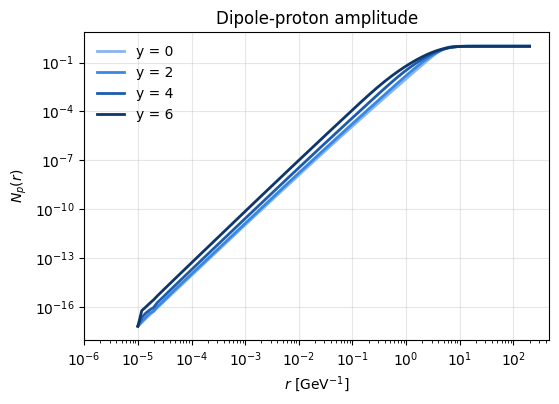

In [35]:
# 1) Dipole-proton amplitude at y = 0, 2, 4, 6
r = np.logspace(-5, np.log10(dip_p.r_range[1]), 400)

fig, ax = plt.subplots(figsize=(6, 4))
for y, c in zip([0, 2, 4, 6], Y_RAMP):
    ax.plot(r, dip_p.N(x_of_y(dip_p, y), r), color=c, lw=2, label=f"y = {y}")
ax.set_xscale("log")
ax.set_xlabel(r"$r$ [GeV$^{-1}$]")
ax.set_ylabel(r"$N_p(r)$")
ax.set_title("Dipole-proton amplitude")
ax.grid(alpha=0.3)
ax.legend(frameon=False)
plt.xlim(left=1e-6)
plt.yscale("log")
plt.show()

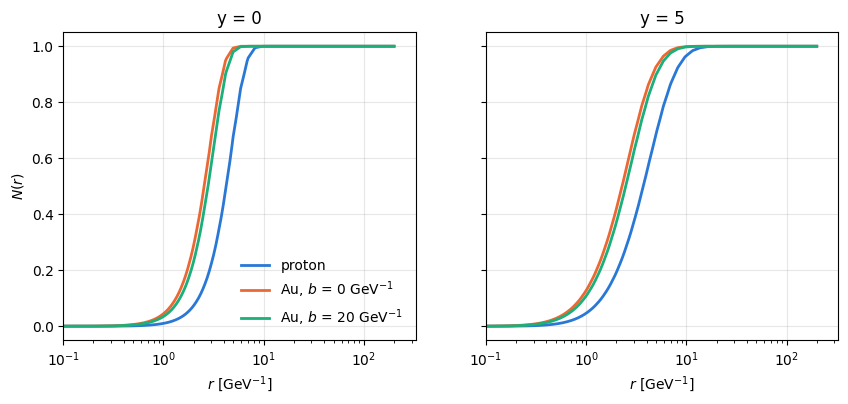

In [36]:
# 2) Proton vs nucleus (b = 0, 12 GeV^-1) at y = 0 and y = 5
r = np.logspace(-2, np.log10(dip_p.r_range[1]), 400)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, y in zip(axes, [0, 5]):
    ax.plot(r, dip_p.N(x_of_y(dip_p, y), r), color=CAT[0], lw=2, label="proton")
    for b, c in [(0, CAT[1]), (20, CAT[2])]:
        ax.plot(r, dip_A.N(x_of_y(dip_A, y), r, b), color=c, lw=2,
                label=rf"Au, $b$ = {b} GeV$^{{-1}}$")
    ax.set_xscale("log")
    ax.set_xlabel(r"$r$ [GeV$^{-1}$]")
    ax.set_title(f"y = {y}")
    ax.grid(alpha=0.3)
    ax.set_xlim(left=0.1)
axes[0].set_ylabel(r"$N(r)$")
axes[0].legend(frameon=False)
plt.show()

b_max = 32 GeV^-1 = 6.31 fm, R_WS = 6.37 fm, fraction of T_A inside: F = 0.9156


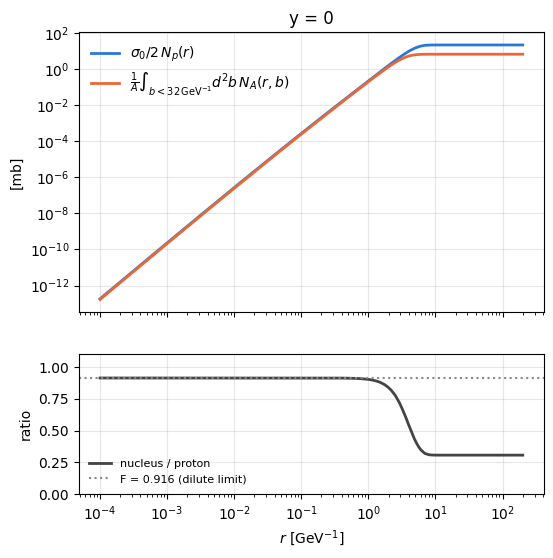

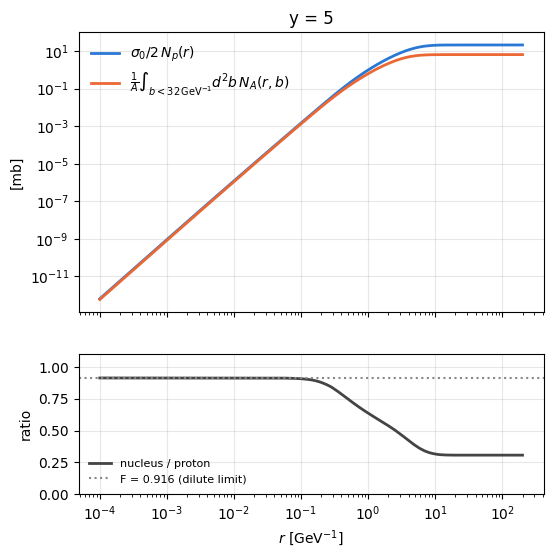

In [37]:
# 3) sigma0/2 * N_p(r)  vs  int d^2b N_A(r, b),  b from 0 to 32 GeV^-1
#
# In the dilute limit (small r) the IC is N_A = A T_A(b) sigma0/2 N_p(r), so
#   int d^2b N_A = A sigma0/2 N_p * F,   F = int_{b<32} d^2b T_A(b)  (= 1 for b -> infinity).
# We therefore plot int d^2b N_A / A and compare to sigma0/2 N_p (and to F * sigma0/2 N_p).
#
# Units: b in GeV^-1 -> int d^2b in GeV^-2. 1 GeV^-2 = (hbar c)^2 = 0.3894 mb.
if nucleus == "Au":
    A = 197
elif nucleus == "Pb":
    A = 208
HBARC = 0.1973269804                  # GeV fm
GEVM2_TO_MB = HBARC**2 * 10.0         # 1 fm^2 = 10 mb  ->  1 GeV^-2 = 0.3894 mb


bgrid = np.linspace(0, 32, 321)       # GeV^-1, fine grid inside the tabulated range

def d2b_NA(x, r):
    """int_0^32 d^2b N_A(x, r, b) in GeV^-2 (trapezoid in b with 2 pi b weight)."""
    R, B = np.meshgrid(r, bgrid, indexing="ij")
    NA = dip_A.N(x, R, B)
    return np.trapezoid(2 * np.pi * B * NA, bgrid, axis=1)

# Fraction of the Woods-Saxon T_A inside b < 32 GeV^-1 (same parameters as generate_ic.py)
R_WS = (1.12 * A**(1/3) - 0.86 * A**(-1/3)) / HBARC   # GeV^-1
D_WS = 0.54 / HBARC
def TA_unnorm(b):
    return 2 * quad(lambda z: 1 / (1 + np.exp((np.hypot(b, z) - R_WS) / D_WS)), 0, R_WS + 30*D_WS + b, limit=200)[0]
norm = 2*np.pi * quad(lambda b: b * TA_unnorm(b), 0, R_WS + 30*D_WS, limit=200)[0]
F = 2*np.pi * quad(lambda b: b * TA_unnorm(b), 0, 32, limit=200)[0] / norm
print(f"b_max = 32 GeV^-1 = {32*HBARC:.2f} fm, R_WS = {R_WS*HBARC:.2f} fm, fraction of T_A inside: F = {F:.4f}")

r = np.logspace(-4, np.log10(dip_p.r_range[1]), 200)
for y in [0, 5]:
    Np_mb = SIGMA02_MB * dip_p.N(x_of_y(dip_p, y), r)
    NA_mb = d2b_NA(x_of_y(dip_A, y), r) * GEVM2_TO_MB / A

    fig, (ax, axr) = plt.subplots(2, 1, figsize=(6, 6), sharex=True,
                                  gridspec_kw={"height_ratios": [2, 1]})
    ax.plot(r, Np_mb, color=CAT[0], lw=2, label=r"$\sigma_0/2\, N_p(r)$")
    ax.plot(r, NA_mb, color=CAT[1], lw=2, label=r"$\frac{1}{A}\int_{b<32\,\mathrm{GeV}^{-1}} d^2b\, N_A(r,b)$")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_ylabel("[mb]")
    ax.set_title(f"y = {y}")
    ax.grid(alpha=0.3)
    ax.legend(frameon=False)

    axr.plot(r, NA_mb / Np_mb, color="#444444", lw=2, label="nucleus / proton")
    axr.axhline(F, color="#888888", ls=":", lw=1.5, label=f"F = {F:.3f} (dilute limit)")
    axr.set_xscale("log")
    axr.set_xlabel(r"$r$ [GeV$^{-1}$]")
    axr.set_ylabel("ratio")
    axr.set_ylim(0, 1.1)
    axr.grid(alpha=0.3)
    axr.legend(frameon=False, fontsize=8)
    plt.show()

Text(0, 0.5, '$N(r)$')

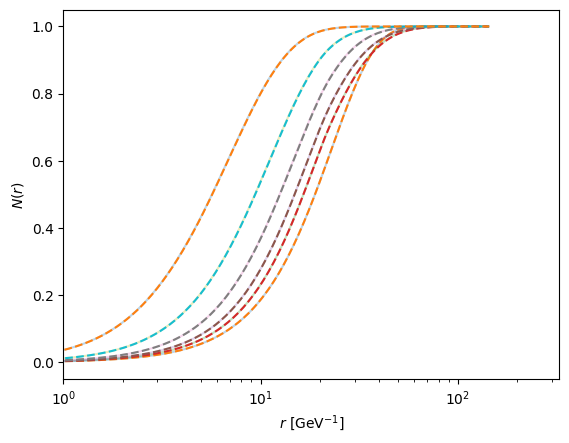

In [38]:
for y in [0,0.5,1,2,4,8]:
    d=np.loadtxt("/Users/hejajama//tmp/nlobkAu/cc_p_y_"+str(y)+".dat")
    plt.plot(d[:,0],d[:,1],label="CC y="+str(y), alpha=0.3)

    try:
        d=np.loadtxt("/Users/hejajama//tmp/nlobkAu/own_p_y_"+str(y)+".dat")
        plt.plot(d[:,0],d[:,1],label="CC Au y="+str(y), linestyle="dashed")
    except:
        continue
plt.xscale("log")
plt.xlim(left=1e-0)
plt.xlabel(r"$r$ [GeV$^{-1}$]")
plt.ylabel(r"$N(r)$")